# 5. Target linear anyon-Hubbard model and energy gaps

**Question:** what does the target density-dependent hopping Hamiltonian
predict, independently of the Rydberg implementation? Sources: thesis
Sec. 1.2 and Appendix C; original `sweepGapsMulti.py`, `doApplyHam.py`,
and `replotGapsMulti.py`.

**Theoretical model:** the Hamiltonian below is imposed. Its generic-angle
spectrum does not demonstrate that the single-tone Rydberg scheme realizes
that model. The archived sweep uses the **full** truncated Hilbert space,
without fixing particle number and without a chemical potential term.

## Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

## 5.1 Local operators, truncation, and operator ordering

In the ordered local basis the truncated bosonic lowering operator is
$$b=\begin{pmatrix}0&1&0\\0&0&\sqrt2\\0&0&0\end{pmatrix},\qquad
  n=b^\dagger b=\operatorname{diag}(0,1,2).$$
It obeys $b|n\rangle=\sqrt n\,|n-1\rangle$ and $b^\dagger|2\rangle=0$.
At the cutoff the usual infinite-dimensional commutator is modified:
$$bb^\dagger=\operatorname{diag}(1,2,0),\quad
  [b,b^\dagger]=\operatorname{diag}(1,1,-2)=I-3|2\rangle\langle2|.$$
The truncation is an explicit model assumption, not an exact representation
of unbounded bosonic occupation.

For an open chain use
$$H=-J\sum_{j=0}^{L-2}\left[b_j^\dagger e^{i\theta n_j}b_{j+1}
  +b_{j+1}^\dagger e^{-i\theta n_j}b_j\right]
  +\frac U2\sum_{j=0}^{L-1}n_j(n_j-1).$$
$J$ and $U$ have energy units, $\theta$ is dimensionless, and both brackets
contain dimensionless operators. The two hopping terms are conjugate
transposes with their order reversed, ensuring Hermiticity.

Act on a bond $|n,m\rangle$ **from right to left**:
$$b_{j+1}|n,m\rangle=\sqrt m\,|n,m-1\rangle,$$
$$e^{i\theta n_j}\sqrt m\,|n,m-1\rangle
   =\sqrt m e^{i\theta n}|n,m-1\rangle,$$
$$b_j^\dagger\sqrt m e^{i\theta n}|n,m-1\rangle
   =\sqrt{(n+1)m}\,e^{i\theta n}|n+1,m-1\rangle.$$
Multiplication by $-J$ gives the implemented matrix element. The reverse
amplitude is its complex conjugate. The four forward processes therefore
have factors $1,\sqrt2,\sqrt2,2$ and phases $0,\theta,0,\theta$.
Their total particle number is unchanged.

Choose a positive reference interaction $U$ and divide by it:
$$K=H/U,\qquad K=-(J/U)\sum_j(\text{hopping}+\text{h.c.})
    +\frac12\sum_jn_j(n_j-1).$$
Eigenvalues of $K$ are $E/U$. This reference $U$ is distinct from the
potentially negative $U_{\rm eff}$ in Notebook 4.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd().resolve()
roots = [p for p in (here, *here.parents) if (p / 'anyon_thesis').is_dir()]
if not roots:
    raise FileNotFoundError('Open this notebook from the cloned repository.')
ROOT = roots[0]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from anyon_thesis.models import (
    EffectiveParameters, effective_bond, effective_chain, occupation_basis,
    phase_pattern, basis_state, evolve_probabilities, parameter_curves,
    target_hamiltonian, lowest_levels, gap_grid,
)
SAVE_FIGURES = False  # Optional export; raw scripts/data are never overwritten.
STYLE = {'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False}
def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / 'notebook_outputs'
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f'{name}.png', dpi=160)
    display(fig)
    plt.close(fig)
np.set_printoptions(precision=6, suppress=True)

In [2]:
b = np.diag(np.sqrt([1., 2.]), 1)
n = b.conj().T @ b
theta = 0.73
phase = np.diag(np.exp(1j*theta*np.diag(n)))
h_local = -(np.kron(b.conj().T @ phase, b)
            + np.kron(phase.conj().T @ b, b.conj().T))
print('b =\n', b)
print('n =\n', n)
print('[b,b^dag] =\n', b @ b.conj().T-b.conj().T @ b)
assert np.allclose(h_local, h_local.conj().T)
assert np.allclose(b @ b.conj().T-b.conj().T @ b, np.diag([1, 1, -2]))

b =
 [[0.       1.       0.      ]
 [0.       0.       1.414214]
 [0.       0.       0.      ]]
n =
 [[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 2.]]
[b,b^dag] =
 [[ 1.  0.  0.]
 [ 0.  1.  0.]
 [ 0.  0. -2.]]


## 5.2 Full-space and fixed-number gaps answer different questions

Write the ordered eigenvalues in sector $N$ as $E_0(N),E_1(N),\ldots$.
A fixed-number excitation is
$$\Delta_N=E_1(N)-E_0(N).$$
If all sectors are combined and ordered, their lowest levels are
$E_0^{\rm all}\leq E_1^{\rm all}\leq\cdots$, giving
$$\Delta_{\rm all}=E_1^{\rm all}-E_0^{\rm all}.$$
The two levels in the latter expression may have different particle numbers.
Neither expression is automatically the charge gap
$E_0(N+1)+E_0(N-1)-2E_0(N)$. State which quantity is computed.

A sparse solver seeks only a few eigenpairs. For a returned normalized
eigenvector $v$, compute the residual $\|Kv-\lambda v\|$; small residuals
test the eigenproblem solution, not the physical model. Degenerate levels
and finite size require care when interpreting small gaps.

In [3]:
small_L, ratio, angle = 4, 0.3, 0.73
full, basis = target_hamiltonian(small_L, ratio, 1.0, angle)
fixed, fixed_basis = target_hamiltonian(small_L, ratio, 1.0, angle, total_number=small_L)
all_levels, residual_all = lowest_levels(full, 5)
fixed_levels, residual_fixed = lowest_levels(fixed, 5)
print('Full space:', len(basis), 'states; lowest levels:', all_levels)
print('Fixed N=L:', len(fixed_basis), 'states; lowest levels:', fixed_levels)
print('Full-space spacing:', all_levels[1]-all_levels[0])
print('Fixed-number spacing:', fixed_levels[1]-fixed_levels[0])
print('Largest residual:', max(residual_all.max(), residual_fixed.max()))
assert max(residual_all.max(), residual_fixed.max()) < 1e-9

Full space: 81 states; lowest levels: [-0.908033 -0.820174 -0.792152 -0.564835 -0.48541 ]
Fixed N=L: 19 states; lowest levels: [-0.820174 -0.122955  0.082948  0.371533  0.486388]
Full-space spacing: 0.08785830338852851
Fixed-number spacing: 0.6972188530873912
Largest residual: 2.8819850364098067e-15


## 5.3 Replot the archived $L=10$ grid without smoothing

The saved array has axes `(J/U index, theta index, level index)`.
It contains five lowest **full-space** levels at every grid point.
Subtracting level zero gives four ground-referenced spacings; subtracting
neighbouring levels 1-2, 2-3, and 3-4 gives three additional spacings.
All plotted differences are divided by the saved reference $U$.

We render the actual grid cells with nearest-cell shading. The original
renderer used Gouraud shading, which visually interpolates between samples.
The numbers are unchanged; these displays intentionally do not claim
information at unsampled points. Each panel has its own labelled colourbar.

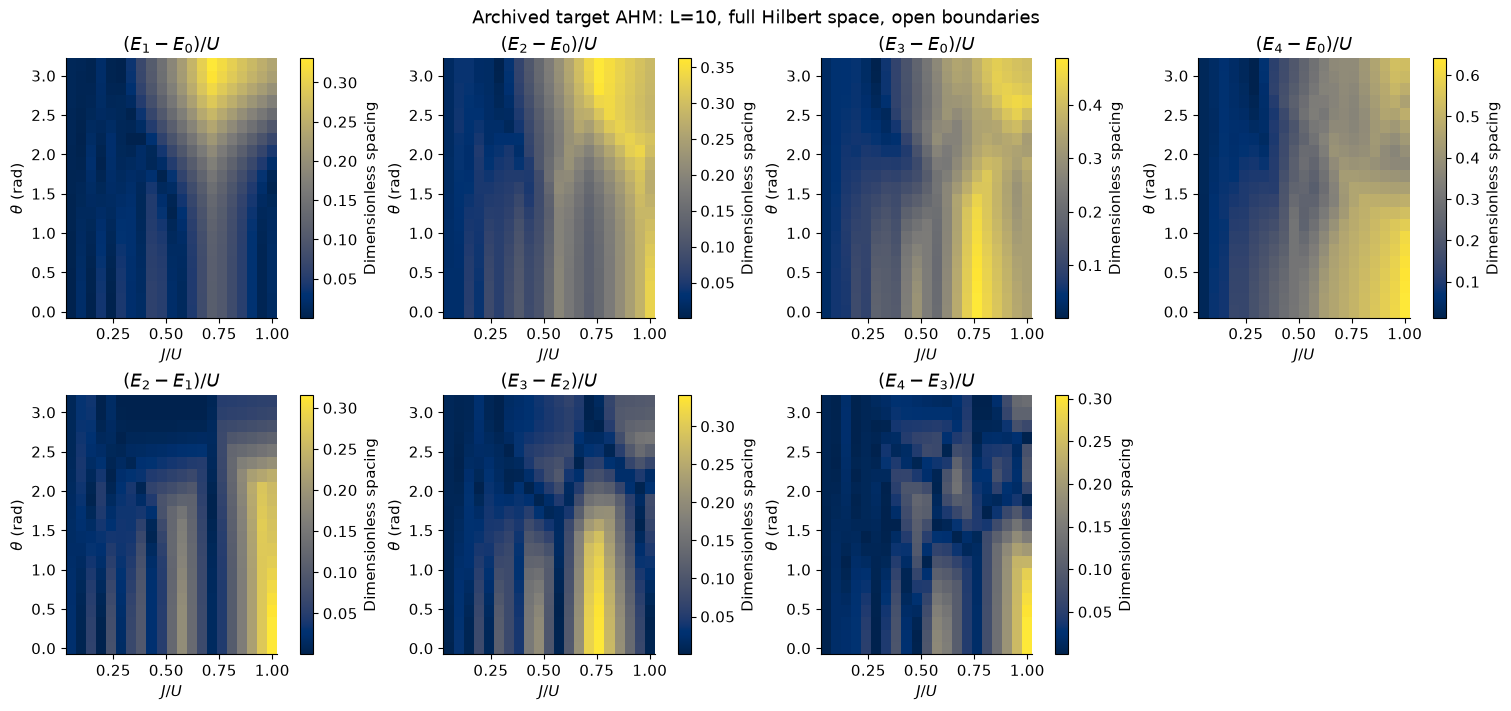

Saved grid shape: (21, 21, 5) ; periodic boundaries: False
First grid point: J/U= 0.05 theta= 0.0 levels/U= [-0.320272 -0.319422 -0.296256 -0.293516 -0.292023]


In [4]:
with np.load(ROOT / 'data/anyonHubbardGapsMulti_N10.npz', allow_pickle=False) as z:
    ratios, angles = z['ratios'].copy(), z['thetas'].copy()
    energies, saved_U = z['energies'].copy(), float(z['U'])
    saved_L, saved_pbc = int(z['Nsites']), bool(z['usePBC'])
assert saved_U > 0
assert energies.shape == (len(ratios), len(angles), 5)
assert np.all(np.diff(energies, axis=-1) >= -1e-10)
differences = [(k, 0) for k in range(1, 5)] + [(k+1, k) for k in range(1, 4)]
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(2, 4, figsize=(15, 7), layout='constrained')
    for ax, (upper, lower) in zip(axes.flat, differences):
        gap = (energies[:, :, upper]-energies[:, :, lower])/saved_U
        image = ax.pcolormesh(ratios, angles, gap.T, cmap='cividis', shading='nearest')
        ax.set(xlabel=r'$J/U$', ylabel=r'$\theta$ (rad)',
               title=fr'$(E_{upper}-E_{lower})/U$')
        fig.colorbar(image, ax=ax, label='Dimensionless spacing')
    axes.flat[-1].axis('off')
    fig.suptitle(f'Archived target AHM: L={saved_L}, full Hilbert space, open boundaries')
    show_figure(fig, '05_cached_gap_maps')
print('Saved grid shape:', energies.shape, '; periodic boundaries:', saved_pbc)
print('First grid point: J/U=', ratios[0], 'theta=', angles[0], 'levels/U=', energies[0,0]/saved_U)

**Figure description:** seven panels show four ground-referenced spacings
and three successive excited-level spacings. Colour encodes each labelled
energy difference on that panel's own scale. These are finite-grid numerical
spectra, and a small global spacing may join different number sectors.

## 5.4 A small sweep that can actually run

The following sweep uses four sites and a coarse grid. It is a teaching
calculation, not a replacement for the saved ten-site results. Set
`RUN_DEMO_SWEEP=False` to skip it. Re-running the original 441-point,
ten-site sweep is a separate expensive choice and is never triggered here.

Demo shape: (5, 5, 3) ; largest eigenpair residual: 6.85957027602518e-15


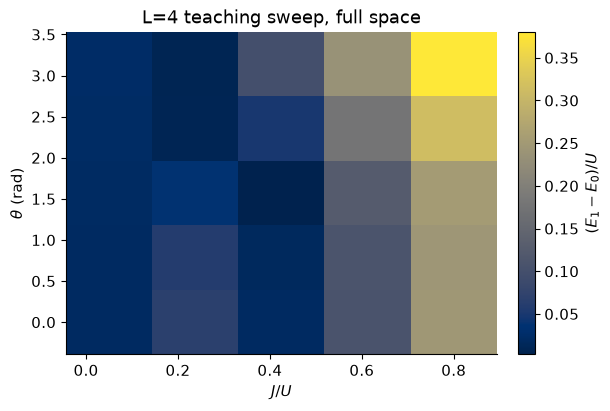

In [5]:
RUN_DEMO_SWEEP = True
if RUN_DEMO_SWEEP:
    demo_ratios = np.linspace(0.05, 0.8, 5)
    demo_angles = np.linspace(0, np.pi, 5)
    demo, residual = gap_grid(4, demo_ratios, demo_angles, count=3)
    print('Demo shape:', demo.shape, '; largest eigenpair residual:', residual)
    assert residual < 1e-9
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
        mesh = ax.pcolormesh(demo_ratios, demo_angles,
                             (demo[:,:,1]-demo[:,:,0]).T,
                             shading='nearest', cmap='cividis')
        ax.set(xlabel=r'$J/U$', ylabel=r'$\theta$ (rad)', title='L=4 teaching sweep, full space')
        fig.colorbar(mesh, ax=ax, label=r'$(E_1-E_0)/U$')
        show_figure(fig, '05_demo_sweep')

## 5.5 Limiting cases and independent numerical checks

At $J=0$, $K=\tfrac12\sum_jn_j(n_j-1)$ is diagonal: a doublon costs one,
and occupations zero or one cost zero. At $\theta=0$, the hopping reduces
to the real truncated Bose-Hubbard hopping. At $\theta+2\pi$, each integer
occupation gives the same phase as at $\theta$, so the matrix repeats.
At $\theta=\pi$, the phase is $(-1)^{n_j}$; because double occupation remains
allowed, this is not the same local Hilbert space as spinless fermions.

The automated tests additionally compare this Fock-space assembly with the
original tensor-contraction operator, for open and periodic chains. That is
an independent implementation check of operator ordering and boundary terms.

In [6]:
zero_hop, cfg = target_hamiltonian(3, 0.0, 1.0, 0.73)
expected = np.sum(cfg*(cfg-1), axis=1)/2
assert np.allclose(zero_hop.toarray(), np.diag(expected))
zero_phase, _ = target_hamiltonian(3, 0.3, 1.0, 0.0)
two_pi, _ = target_hamiltonian(3, 0.3, 1.0, 2*np.pi)
assert np.allclose(zero_phase.toarray(), two_pi.toarray(), atol=1e-13)
assert np.allclose(zero_phase.toarray().imag, 0)
number_operator = np.diag(cfg.sum(axis=1))
K, _ = target_hamiltonian(3, 0.3, 1, 0.73)
assert np.allclose(K.toarray() @ number_operator, number_operator @ K.toarray())
print('Zero hopping, Bose limit, 2 pi periodicity, number conservation: PASS')

Zero hopping, Bose limit, 2 pi periodicity, number conservation: PASS


## Sources and limits of this notebook

- Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de
  Barcelona, 2026: [institutional record](https://hdl.handle.net/2445/231684).
  See the relevant sections and equations identified above.
- [Archived thesis and code deposit](https://doi.org/10.5281/zenodo.23443035).
- Original scripts in [`scripts/`](../scripts/) at source commit
  `22959963191fcbc4d283ec4b272b506ad6dd979b`; this notebook is a new explanatory
  implementation. The original script and data bytes are preserved.
- [SciPy `eigsh` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.eigsh.html)
  for the sparse eigenvalue solver. For complex Hermitian input, SciPy uses
  its complex eigensolver internally; residual checks remain necessary.

These finite-size calculations do not independently validate the microscopic
derivation, establish an experimental realization, or prove a thermodynamic
phase transition. No new empirical evidence is introduced.